# Ensemble Methods

In [13]:
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

In [14]:
# Load the classification data and create a stratified holdout set.
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")
print(f"Features: {X.shape[1]}")

Training samples: 455
Testing samples: 114
Features: 30


## Bagging and boosting models

The Bagging model below uses fully grown decision trees trained on bootstrap samples. Random Forest uses bootstrap samples plus random subsets of features at each split. AdaBoost uses shallow decision trees as weak learners and updates their weights over successive rounds.

In [15]:
models = {
    "Bagging": BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=100,
        max_samples=1.0,
        bootstrap=True,
        random_state=42,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_features="sqrt",
        random_state=42,
    ),
    "AdaBoost": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
        n_estimators=100,
        learning_rate=0.5,
        random_state=42,
    ),
}

results = []
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predicted_classes = model.predict(X_test)
    predicted_probabilities = model.predict_proba(X_test)[:, 1]
    predictions[name] = predicted_classes
    results.append(
        {
            "Model": name,
            "Accuracy": accuracy_score(y_test, predicted_classes),
            "F1": f1_score(y_test, predicted_classes),
            "ROC-AUC": roc_auc_score(y_test, predicted_probabilities),
        }
    )
results_table = pd.DataFrame(results).set_index("Model")
results_table.round(4)

,Accuracy,F1,ROC-AUC
Model,,,
Bagging,0.9386,0.9517,0.9927
Random Forest,0.9561,0.9655,0.9937
AdaBoost,0.9561,0.9660,0.9835


In [16]:
# Compare the number of component learners and feature importance.
model_summary = pd.DataFrame(
    {
        "Component learners": [
            len(models["Bagging"].estimators_),
            len(models["Random Forest"].estimators_),
            len(models["AdaBoost"].estimators_),
        ],
        "Learning strategy": [
            "Independent bootstrap trees",
            "Bootstrap trees + random features",
            "Sequential weighted weak learners",
        ],
    },
    index=models.keys(),
)
model_summary

,Component learners,Learning strategy
Bagging,100,Independent bootstrap trees
Random Forest,100,Bootstrap trees + random features
AdaBoost,100,Sequential weighted weak learners


In [17]:
# Display detailed metrics for Random Forest.
print(
    classification_report(
        y_test,
        predictions["Random Forest"],
        target_names=data.target_names,
    )
)

              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



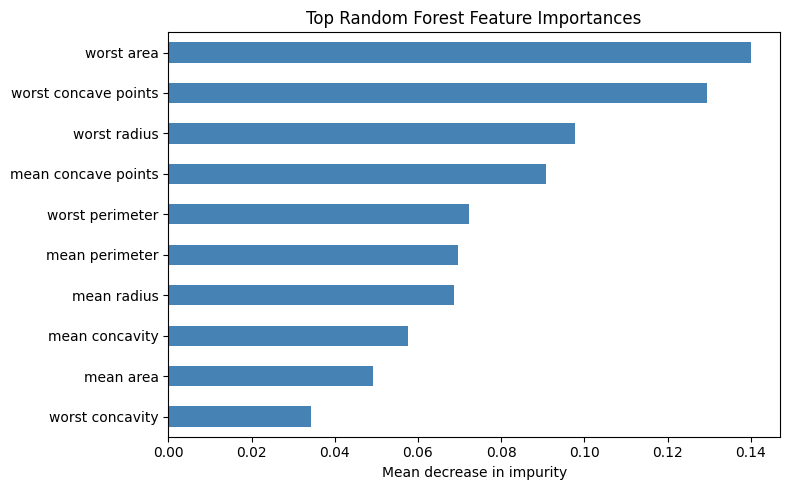

In [18]:
# Visualize the most important Random Forest features.
importance = pd.Series(
    models["Random Forest"].feature_importances_,
    index=X.columns,
).sort_values(ascending=False).head(10).sort_values()

importance.plot(kind="barh", figsize=(8, 5), color="steelblue")
plt.xlabel("Mean decrease in impurity")
plt.title("Top Random Forest Feature Importances")
plt.tight_layout()
plt.show()

### Analysis

Bagging reduces variance by averaging diverse bootstrap-trained trees. Random Forest generally decorrelates the trees further through random feature selection. AdaBoost reduces bias by focusing later weak learners on difficult examples. The metric table should be interpreted together with the learning strategy, rather than assuming that one ensemble is always best for every dataset.